# Final Pareto plots — reward vs. control energy

Two unconstrained reward problems on two-moons (`N=16`, flow-map checkpoint `two_moons_paper_lsd_15.pkl`):

| | reward | data | λ range |
|---|---|---|---|
| **A** | upper-moon RBF (σ=0.35, 400 ref. points) | `results/unconstrained_pareto_v4/sweep_results_merged.csv` | 0.1 – 10 |
| **B** | off-top ball (p=(-0.1,1.75), σ=0.5) | `results/offtop_lambda_saturation/sweep_results_merged.csv` | 0.1 – 100000 |

Each point is the **best configuration at that λ**, selected by `objective_J = ctrl_cost_obj − avg_r_ctrl`
over the inner hyperparameter grid (`mpc_n_iters`, `mpc_lr`, `hf_n_outer`, `fmrg_n_iters`, …).

**All styling knobs live in the `STYLE` / `SERIES_*` cells below** — edit those, then re-run the plot cell.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

RESULTS = Path("results")

# Raw sweep outputs. Each run of run_sweep.py writes its own directory, and the
# CSV schema grew over time (constraint_margin / adaptive-dual / 5-constraint
# columns were added), so runs cannot be appended into one file on disk --
# they are concatenated here instead, which aligns columns by name and fills
# the missing ones with NaN.
UPPER_MOON_PARTS = [
    RESULTS / "unconstrained_pareto_v3" / "sweep_results_all2.csv",  # lam 0.1 - 3
    RESULTS / "unconstrained_pareto_v4" / "sweep_results.csv",       # lam 5, 10 + H=8,16
]
OFFTOP_PARTS = [
    RESULTS / "offtop_pareto"            / "sweep_results_full2.csv",  # lam 0.1 - 100
    RESULTS / "offtop_extended"          / "sweep_results.csv",        # lam 200 - 2000, H=8,16
    RESULTS / "offtop_lambda_saturation" / "sweep_results.csv",        # lam 5000 - 100000
]


def load_sweep(parts, restrict_grid=False):
    """Concatenate sweep CSVs into one dataframe.

    restrict_grid=True keeps a single inner-solver grid so that points run at
    different times are selected from the same set of configs:
        MPC      -> mpc_n_iters == 50
        HardFlow -> hf_n_outer == 10 and hf_n_inner == 10
        FMRG     -> unrestricted
    Needed for the upper-moon figure, whose lam<=3 and lam in {5,10} points were
    swept with different grids. Set False to select over every config available.
    """
    df = pd.concat([pd.read_csv(f) for f in parts], ignore_index=True)
    if restrict_grid:
        keep = (
            ((df.method == "mpc")      & (df.mpc_n_iters == 50)) |
            ((df.method == "hardflow") & (df.hf_n_outer == 10) & (df.hf_n_inner == 10)) |
            (df.method == "fmrg")
        )
        df = df[keep]
    return df.reset_index(drop=True)

%matplotlib inline


## 1. Global style knobs

Figure-level settings. Per-series colour / marker / size live in the `SERIES_*` dicts further down.

In [2]:
STYLE = dict(
    figsize        = (10.5, 7.5),
    dpi            = 150,
    marker_size    = 75,      # default scatter size; per-series `s` overrides this
    marker_edge    = "black",
    marker_edge_lw = 0.5,
    marker_alpha   = 0.95,
    line_lw        = 1.2,     # the faint connector through each series
    line_alpha      = 0.5,
    draw_lines     = True,    # False -> pure scatter
    annotate_lam   = True,    # write the λ value next to each point
    annot_fontsize = 6.0,
    annot_offset   = (5, 4),
    legend_fontsize= 8.5,
    legend_loc     = "lower right",
    grid           = False,
    grid_alpha     = 0.25,
    baseline_color = "gray",  # uncontrolled-reward reference line
    baseline_lw    = 1.0,
    baseline_ls    = "--",
    xlabel         = r"Total control energy  $\sum_j \|\Delta x_j\|^2$",
    ylabel         = r"Terminal reward  $\bar r(x_N)$",
)

## 2. Helpers

`select_series` slices the dataframe into named series; `best_per_lam` keeps the single best
config at each λ. Neither does any styling.

In [3]:
def mpc(df, H, constraint_on):
    """MPC rows for one (horizon, constraint-evaluation-point) pair."""
    return df[(df.method == "mpc") & (df.H == H) & (df.constraint_on == constraint_on)]

def hardflow(df):
    return df[df.method == "hardflow"]

def fmrg(df, variant):
    return df[(df.method == "fmrg") & (df.fmrg_variant == variant)]


def best_per_lam(sub, by="objective_J"):
    """One row per λ: the config minimising `by` (objective_J = cost − reward)."""
    sub = sub.dropna(subset=[by])
    if not len(sub):
        return sub
    return sub.loc[sub.groupby("lam")[by].idxmin()].sort_values("ctrl_cost_raw")


def plot_pareto(series, baseline=None, xscale="linear", xlim=None, ylim=None,
                title=None, style=None, ax=None, lam_filter=None):
    """Scatter (+ optional connector) of reward vs. control energy.

    series     : {label: (dataframe, style_overrides_dict)}
    baseline   : uncontrolled reward, drawn as a horizontal reference line
    lam_filter : optional callable, e.g. `lambda l: l != 70`, applied per series
    """
    st = {**STYLE, **(style or {})}
    if ax is None:
        fig, ax = plt.subplots(figsize=st["figsize"])
    else:
        fig = ax.figure

    for label, (sub, override) in series.items():
        b = best_per_lam(sub)
        if lam_filter is not None and len(b):
            b = b[b.lam.map(lam_filter)]
        if not len(b):
            continue
        color  = override.get("color", "C0")
        marker = override.get("marker", "o")
        size   = override.get("s", st["marker_size"])

        if st["draw_lines"]:
            ax.plot(b.ctrl_cost_raw, b.avg_r_ctrl, color=color,
                    lw=st["line_lw"], alpha=st["line_alpha"], zorder=2)
        ax.scatter(b.ctrl_cost_raw, b.avg_r_ctrl, color=color, marker=marker, s=size,
                   label=label, edgecolor=st["marker_edge"],
                   linewidth=st["marker_edge_lw"], alpha=st["marker_alpha"], zorder=3)
        if st["annotate_lam"]:
            for _, r in b.iterrows():
                ax.annotate(f"{r.lam:g}", (r.ctrl_cost_raw, r.avg_r_ctrl),
                            textcoords="offset points", xytext=st["annot_offset"],
                            fontsize=st["annot_fontsize"], color=color, alpha=0.9)

    if baseline is not None:
        ax.axhline(baseline, color=st["baseline_color"], lw=st["baseline_lw"],
                   ls=st["baseline_ls"], label=f"Uncontrolled (r={baseline:.3f})")

    ax.set_xscale(xscale)
    if xlim: ax.set_xlim(*xlim)
    if ylim: ax.set_ylim(*ylim)
    ax.set_xlabel(st["xlabel"] + ("  (log scale)" if xscale == "log" else ""))
    ax.set_ylabel(st["ylabel"])
    if title: ax.set_title(title)
    if st["grid"]: ax.grid(alpha=st["grid_alpha"], zorder=0)
    ax.legend(fontsize=st["legend_fontsize"], loc=st["legend_loc"])
    fig.tight_layout()
    return fig, ax

---
# 0. The two reward functions

Both rewards drawn on one set of axes, each in its own colour: filled alpha-gradient
(transparent → saturated as $r\to1$) plus a few labelled level curves.

> **Note on the definitions.** These mirror `run_sweep._build_reward_fn` exactly, but are
> re-implemented here rather than imported: `run_sweep.py` calls `matplotlib.use("Agg")` at
> module level, which would override `%matplotlib inline` and stop figures rendering in the
> notebook. If you edit the rewards in `run_sweep.py`, mirror the change here.

In [4]:
from matplotlib.colors import LinearSegmentedColormap, to_rgba
from scipy.spatial import cKDTree
from sampling_utils import sample_two_moons   # safe to import (no matplotlib side effects)

# ---- constants, mirroring run_sweep.py --------------------------------------
REWARD_SIGMA   = 0.35                      # upper-moon RBF bandwidth
N_REF          = 400                       # upper-moon reference points
OFFTOP_CENTER  = np.array([-0.1, 1.75])    # off-top ball centre
OFFTOP_SIGMA   = 0.5                       # off-top ball bandwidth


def upper_moon_reward(P, seed=42):
    """r(x) = exp(-min_j ||x - x_j||^2 / 2 sigma^2) over N_REF upper-moon points."""
    rng = np.random.default_rng(seed)
    pts, labels = sample_two_moons(50_000, return_labels=True)
    upper = pts[labels == 0]
    ref = upper[rng.choice(len(upper), N_REF, replace=False)]
    d, _ = cKDTree(ref).query(P)          # nearest-reference distance
    return np.exp(-d**2 / (2 * REWARD_SIGMA**2))


def offtop_ball_reward(P):
    """r(x) = exp(-||x - p||^2 / 2 sigma^2), a single bump off the data manifold."""
    d2 = ((P - OFFTOP_CENTER) ** 2).sum(-1)
    return np.exp(-d2 / (2 * OFFTOP_SIGMA**2))

### Style knobs for the reward figure

In [46]:
REWARD_STYLE = dict(
    figsize      = (8.0, 8.0),
    extent       = 2.7,          # plot spans [-extent, extent]^2
    grid         = 400,          # evaluation resolution per axis
    fill_levels  = 10,           # filled-contour resolution
    fill_vmax    = 1.0,
    line_levels  = (0.3, 0.6, 0.9),
    line_lw      = 1.3,
    line_alpha   = 0.9,
    clabel_fs    = 20,
    moon_size    = 3,
    moon_alpha   = 0.30,
    moon_color   = "0.35",
    legend_fs    = 20,
)

def rgba(r, g, b, a=1.0):
    """Matplotlib RGBA from 0–255 RGB and alpha in [0, 1]."""
    return (r / 255, g / 255, b / 255, a)


# one colour per reward — tune R, G, B in [0, 255] and alpha in [0, 1]
REWARD_COLORS = {
    "upper-moon": rgba(34, 148, 127, 0.5),   # blue
    "off-manifold":   rgba(214, 109, 24, 1.0),    # red
}


def alpha_cmap(color):
    """Colormap from fully transparent to `color` at its alpha."""
    rgba = to_rgba(color)
    return LinearSegmentedColormap.from_list(
        "", [(rgba[0], rgba[1], rgba[2], 0.0), rgba]
    )

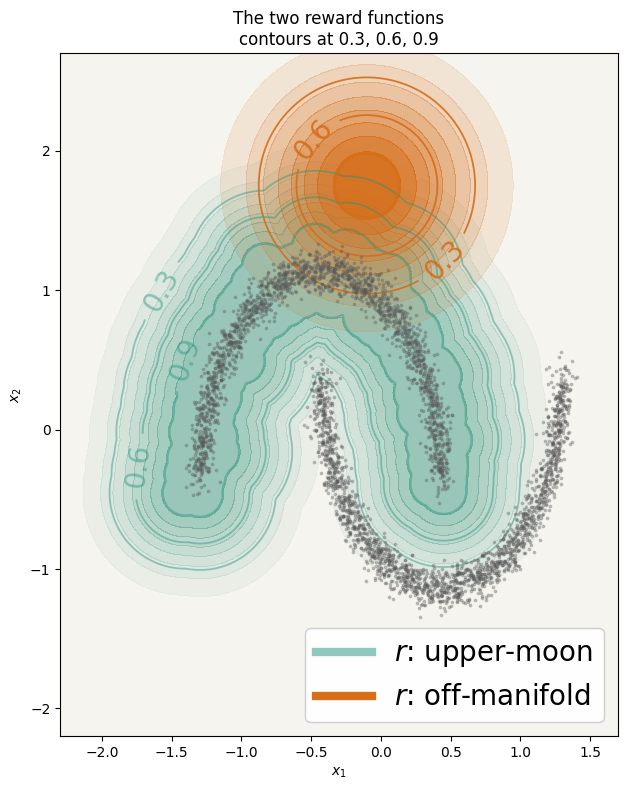

In [47]:
st = REWARD_STYLE
E, G = st["extent"], st["grid"]
xs = np.linspace(-E, E, G)
XX, YY = np.meshgrid(xs, xs, indexing="xy")
P = np.stack([XX.ravel(), YY.ravel()], axis=1)

R = {
    "upper-moon": upper_moon_reward(P).reshape(G, G),
    "off-manifold":   offtop_ball_reward(P).reshape(G, G),
}

pts, labels = sample_two_moons(4000, return_labels=True)

fig, ax = plt.subplots(figsize=st["figsize"])

for name, Z in R.items():
    color = REWARD_COLORS[name]
    rgb, a = color[:3], color[3]
    ax.contourf(XX, YY, Z, levels=np.linspace(0, st["fill_vmax"], st["fill_levels"]),
                cmap=alpha_cmap(color), vmin=0, vmax=st["fill_vmax"], zorder=2)
    cs = ax.contour(XX, YY, Z, levels=list(st["line_levels"]), colors=[rgb],
                    linewidths=st["line_lw"], alpha=a * st["line_alpha"], zorder=3)
    ax.clabel(cs, inline=True, fontsize=st["clabel_fs"], fmt="%.1f")
    ax.plot([], [], color=rgb, lw=6, alpha=a, label=f"$r$: {name}")

# data drawn last, on top, so it stays visible through the reward fields
ax.scatter(pts[:, 0], pts[:, 1], s=st["moon_size"], alpha=st["moon_alpha"],
           c=st["moon_color"], zorder=6)

# ax.scatter(*OFFTOP_CENTER, marker="x", s=70, c="black", zorder=7)
# ax.annotate("ball centre", OFFTOP_CENTER + np.array([0.07, 0.05]), fontsize=8, zorder=7)

ax.set_xlim(-2.3, 1.7); ax.set_ylim(-2.2, 2.7); ax.set_aspect("equal")
ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$")
ax.set_title("The two reward functions\n"
             "contours at " + ", ".join(f"{l:g}" for l in st["line_levels"]))
ax.legend(fontsize=st["legend_fs"], loc="lower right", framealpha=0.95)
fig.tight_layout()
fig.savefig(RESULTS / "rewards_both.png", dpi=STYLE["dpi"], bbox_inches="tight")


---
# A. Upper-moon RBF reward

λ ∈ [0.1, 3]. All methods saturate near r≈1 here — this reward is easy enough that
the uncontrolled flow already scores 0.58.

In [4]:
# restrict_grid=True -> lam<=3 (v3 sweep) and lam in {5,10} (v4) use the same
# inner grid. Costs HardFlow ~0.01 reward at lam<=0.25 vs its best-of-24
# selection; set False to let every config compete (curve becomes inconsistent).
df_um = load_sweep(UPPER_MOON_PARTS, restrict_grid=True)
baseline_um = float(df_um.avg_r_unc.dropna().iloc[0])
print(f"{len(df_um)} rows, uncontrolled baseline r = {baseline_um:.4f}")

# ---- per-series style: edit colours / markers / sizes here -------------------
SERIES_UM = {
    "MPC (H=4, horizon)":  (mpc(df_um, 4,  "horizon"),  dict(color="tomato",     marker="o")),
    "MPC (H=4, endpoint)": (mpc(df_um, 4,  "endpoint"), dict(color="darkred",    marker="o")),
    "MPC (H=8, horizon)":  (mpc(df_um, 8,  "horizon"),  dict(color="darkorange", marker="P")),
    "MPC (H=16, horizon)": (mpc(df_um, 16, "horizon"),  dict(color="goldenrod",  marker="*", s=150)),
    "MPC (H=1, endpoint)": (mpc(df_um, 1,  "endpoint"), dict(color="orange",     marker="D")),
    "MPC (H=2, endpoint)": (mpc(df_um, 2,  "endpoint"), dict(color="gold",       marker="D")),
    "HardFlow":            (hardflow(df_um),            dict(color="seagreen",   marker="s")),
    "FMRG (J)":            (fmrg(df_um, "J"),           dict(color="steelblue",  marker="^")),
    "FMRG (E)":            (fmrg(df_um, "E"),           dict(color="navy",       marker="^")),
}


336 rows, uncontrolled baseline r = 0.5889


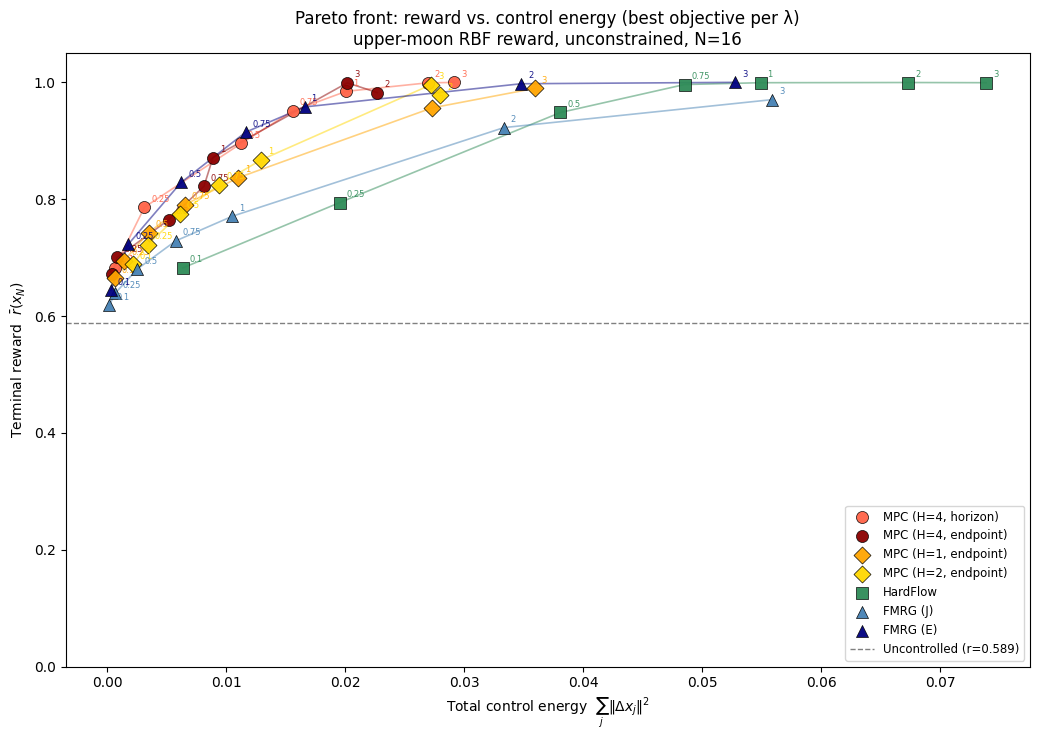

In [5]:
fig, ax = plot_pareto(
    SERIES_UM,
    baseline = baseline_um,
    xscale   = "linear",            # "log" for the log-x version
    ylim     = (0.0, 1.05),
    title    = "Pareto front: reward vs. control energy (best objective per λ)\n"
               "upper-moon RBF reward, unconstrained, N=16",
)
fig.savefig(RESULTS / "unconstrained_pareto_v3" / "pareto_upper_moon_final.png",
            dpi=STYLE["dpi"], bbox_inches="tight")

---
# B. Off-top ball reward

λ ∈ [0.1, 100000]. The target sits **off** the data manifold, so this separates the methods:
horizon-mode MPC saturates near r≈0.98, endpoint-mode plateaus lower (~0.92), FMRG stalls ~0.53.

Series here differ from **A**: H=8 and H=16 (horizon) replace H=1/H=2 (endpoint).

In [6]:
df_ot = load_sweep(OFFTOP_PARTS)   # one grid throughout, no restriction needed
baseline_ot = float(df_ot.avg_r_unc.dropna().iloc[0])
print(f"{len(df_ot)} rows, uncontrolled baseline r = {baseline_ot:.4f}")

# ---- per-series style: edit colours / markers / sizes here -------------------
SERIES_OT = {
    "MPC (H=4, horizon)":  (mpc(df_ot, 4,  "horizon"),  dict(color="tomato",     marker="o")),
    "MPC (H=4, endpoint)": (mpc(df_ot, 4,  "endpoint"), dict(color="darkred",    marker="o")),
    "MPC (H=8, horizon)":  (mpc(df_ot, 8,  "horizon"),  dict(color="darkorange", marker="P")),
    "MPC (H=16, horizon)": (mpc(df_ot, 16, "horizon"),  dict(color="goldenrod",  marker="*", s=150)),
    "HardFlow":            (hardflow(df_ot),            dict(color="seagreen",   marker="s")),
    "FMRG (J)":            (fmrg(df_ot, "J"),           dict(color="steelblue",  marker="^")),
    "FMRG (E)":            (fmrg(df_ot, "E"),           dict(color="navy",       marker="^")),
}

# λ=70 was dropped from earlier versions of this figure; set to None to keep everything.
LAM_FILTER_OT = lambda l: l != 70

798 rows, uncontrolled baseline r = 0.0623


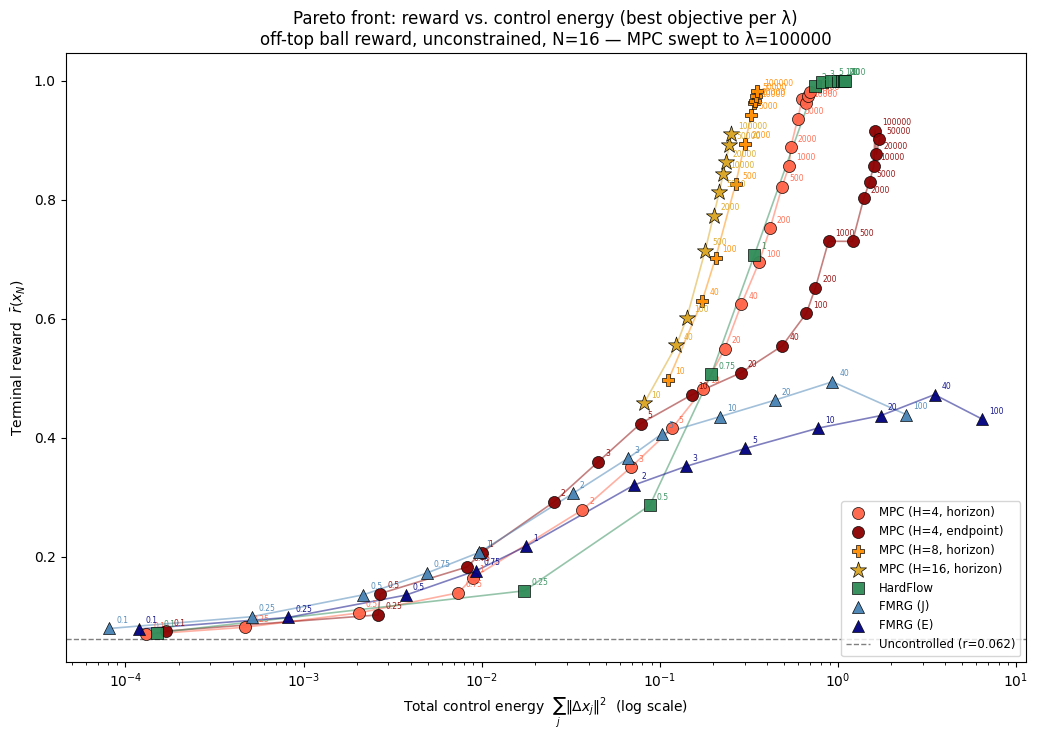

In [7]:
# log-x: shows the full 5-decade sweep including the cheap low-λ end
fig, ax = plot_pareto(
    SERIES_OT,
    baseline   = baseline_ot,
    xscale     = "log",
    lam_filter = LAM_FILTER_OT,
    title      = "Pareto front: reward vs. control energy (best objective per λ)\n"
                 "off-top ball reward, unconstrained, N=16 — MPC swept to λ=100000",
    style      = dict(annot_fontsize=5.5),
)
fig.savefig(RESULTS / "offtop_lambda_saturation" / "pareto_offtop_final_logx.png",
            dpi=STYLE["dpi"], bbox_inches="tight")

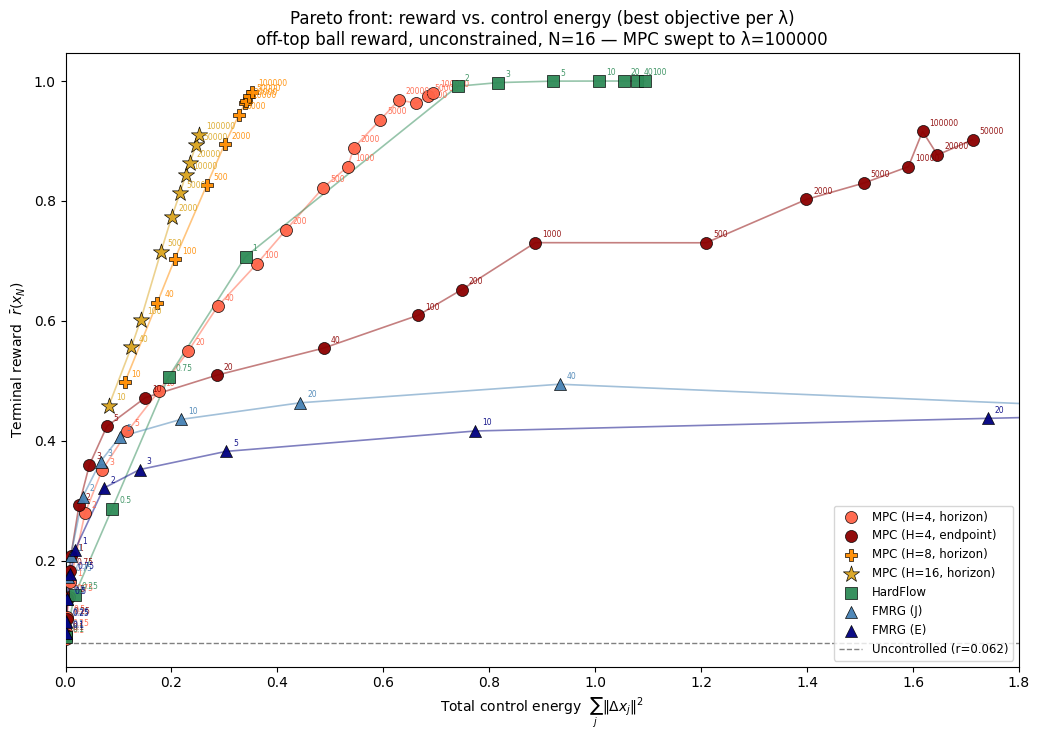

In [8]:
# linear-x: crops the FMRG tail (which runs out to ~5.5) to keep the interesting region readable
fig, ax = plot_pareto(
    SERIES_OT,
    baseline   = baseline_ot,
    xscale     = "linear",
    xlim       = (0, 1.8),
    lam_filter = LAM_FILTER_OT,
    title      = "Pareto front: reward vs. control energy (best objective per λ)\n"
                 "off-top ball reward, unconstrained, N=16 — MPC swept to λ=100000",
    style      = dict(annot_fontsize=5.5),
)
fig.savefig(RESULTS / "offtop_lambda_saturation" / "pareto_offtop_final_linx.png",
            dpi=STYLE["dpi"], bbox_inches="tight")

---
## C. Summary table — control energy needed to reach a given reward

Useful as the numeric companion to the figures (this is what the Pareto ordering amounts to).

In [9]:
def cost_at_reward(series, targets=(0.7, 0.85, 0.95, 0.98)):
    rows = []
    for label, (sub, _) in series.items():
        if not len(sub):
            continue
        row = {"series": label}
        for t in targets:
            ok = sub[sub.avg_r_ctrl >= t]
            row[f"r>={t}"] = round(ok.ctrl_cost_raw.min(), 3) if len(ok) else np.nan
        row["max r"] = round(sub.avg_r_ctrl.max(), 4)
        rows.append(row)
    return pd.DataFrame(rows)

print("UPPER MOON\n", cost_at_reward(SERIES_UM, targets=(0.7, 0.85, 0.95, 0.99)).to_string(index=False))
print("\nOFF-TOP BALL\n", cost_at_reward(SERIES_OT).to_string(index=False))

UPPER MOON
              series  r>=0.7  r>=0.85  r>=0.95  r>=0.99  max r
 MPC (H=4, horizon)   0.003    0.009    0.016    0.027 0.9998
MPC (H=4, endpoint)   0.001    0.007    0.016    0.019 0.9992
MPC (H=1, endpoint)   0.003    0.027    0.027      NaN 0.9897
MPC (H=2, endpoint)   0.001    0.013    0.023    0.027 0.9966
           HardFlow   0.019    0.038    0.049    0.049 0.9998
           FMRG (J)   0.006    0.033    0.056      NaN 0.9704
           FMRG (E)   0.002    0.012    0.017    0.035 1.0000

OFF-TOP BALL
              series  r>=0.7  r>=0.85  r>=0.95  r>=0.98  max r
 MPC (H=4, horizon)   0.416    0.532    0.620    0.694 0.9805
MPC (H=4, endpoint)   0.835    1.128      NaN      NaN 0.9160
 MPC (H=8, horizon)   0.206    0.300    0.339    0.350 0.9824
MPC (H=16, horizon)   0.178    0.235      NaN      NaN 0.9102
           HardFlow   0.340    0.663    0.663    0.740 1.0000
           FMRG (J)     NaN      NaN      NaN      NaN 0.5296
           FMRG (E)     NaN      NaN      N